# Breadth-First Search (BFS) and Depth-First Search (DFS)


## 1. Introduction and Objectives

**Aim:** To understand and implement two basic ways of exploring a graph:
- **Breadth-First Search (BFS)**, which uses a **queue**
- **Depth-First Search (DFS)**, which uses a **stack**

**This notebook assumes you know nothing about these topics.** Everything is built up step by step:

1. What a graph is (Section 2)
2. What a queue and a stack are (Section 3)
3. BFS, with every queue operation printed (Section 4)
4. DFS, with every stack operation printed (Section 5)
5. BFS and DFS compared side by side (Section 6)
6. How fast they are (Section 7)

**Two versions of each algorithm:** for both BFS and DFS you get (a) a **verbose version** that prints every operation, so you can understand what happens, and (b) a **short version** with no printing and only the logic the algorithm needs. The short version is the one you are expected to write yourself.

**How to use it:** run the cells from top to bottom. The printed traces are the main learning tool: read them line by line and compare them with the picture of the graph.

In [2]:
from collections import deque       # deque will be our QUEUE
import io
import time
import random
from contextlib import redirect_stdout

import matplotlib.pyplot as plt
import networkx as nx

plt.rcParams["figure.dpi"] = 110

## 2. What is a Graph?

A **graph** is a way of describing *things* and the *connections* between them. Examples: cities and roads, people and friendships, web pages and links.

| Word | Meaning | Example |
|---|---|---|
| **Vertex** (or node) | A "thing" | A city |
| **Edge** | A connection between two vertices | A road between two cities |
| **Neighbours** of a vertex | All vertices directly connected to it | Cities you can reach by one road |
| **Traversal** | Visiting every reachable vertex, one at a time, in some systematic order | Touring all cities |
| **Visited** | A vertex we have already processed (so we never process it twice) | A city you have already toured |

We will use this small graph throughout the notebook. Its vertices are the letters A to F, and each line is an edge:

```
          A
         / \
        B   C
       / \   \
      D   E---F
```

So A is connected to B and C; B is connected to A, D and E; and so on.

### How do we store a graph in a program?
We use an **adjacency list**: a Python dictionary where each vertex is a key, and its value is the list of its neighbours.

In [3]:
graph = {
    'A': ['B', 'C'],
    'B': ['A', 'D', 'E'],
    'C': ['A', 'F'],
    'D': ['B'],
    'E': ['B', 'F'],
    'F': ['C', 'E'],
}

print("Adjacency list (vertex -> its neighbours):")
for vertex, neighbours in graph.items():
    print(f"  {vertex} -> {neighbours}")

V = len(graph)
E = sum(len(n) for n in graph.values()) // 2   # each edge is listed twice (once per end)
print(f"\nNumber of vertices V = {V}")
print(f"Number of edges    E = {E}")

Adjacency list (vertex -> its neighbours):
  A -> ['B', 'C']
  B -> ['A', 'D', 'E']
  C -> ['A', 'F']
  D -> ['B']
  E -> ['B', 'F']
  F -> ['C', 'E']

Number of vertices V = 6
Number of edges    E = 6


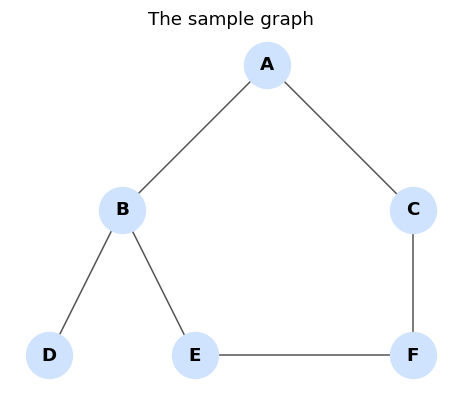

In [4]:
# Fixed positions so the picture matches the ASCII drawing above
pos = {'A': (0, 2), 'B': (-1, 1), 'C': (1, 1), 'D': (-1.5, 0), 'E': (-0.5, 0), 'F': (1, 0)}

def build_nx(graph):
    G = nx.Graph()
    for u, nbrs in graph.items():
        for v in nbrs:
            G.add_edge(u, v)
    return G

plt.figure(figsize=(4, 3.2))
nx.draw(build_nx(graph), pos, with_labels=True, node_color="#cfe3ff",
        edge_color="#555", node_size=900, font_weight="bold")
plt.title("The sample graph")
plt.show()

## 3. Two Simple Tools: the Queue and the Stack

BFS and DFS differ in only one thing: **which waiting list they use to remember the vertices still to be explored**. So we first need to understand the two kinds of waiting list.

### 3.1 Queue: "first come, first served" (FIFO)
Think of people standing in line at a ticket counter.
- A new person joins at the **BACK** of the line. This operation is called **ENQUEUE**.
- The person who is served leaves from the **FRONT** of the line. This operation is called **DEQUEUE**.
- The person who arrived **first** leaves **first**. This rule is called **FIFO** (First In, First Out).

### 3.2 Stack: "last come, first served" (LIFO)
Think of a pile of plates.
- A new plate is placed on the **TOP** of the pile. This operation is called **PUSH**.
- A plate is taken from the **TOP** as well. This operation is called **POP**.
- The plate placed **last** is taken **first**. This rule is called **LIFO** (Last In, First Out).

The cell below defines two helper functions that draw a queue and a stack as text, and then demonstrates both structures with a few names.

In [5]:
def show_queue(q):
    """Return a text picture of a queue: the FRONT is on the left, the BACK on the right."""
    if len(q) == 0:
        return "FRONT -> (empty) <- BACK"
    boxes = "".join(f"[ {x} ]" for x in q)
    return f"FRONT -> {boxes} <- BACK"


def show_stack(s, indent="      "):
    """Print a text picture of a stack: the TOP is drawn at the top."""
    if len(s) == 0:
        print(f"{indent}| (empty) |")
        print(f"{indent}+---------+")
        return
    for i, x in enumerate(reversed(s)):          # last item in the list = top of the stack
        tag = "   <- TOP" if i == 0 else ""
        print(f"{indent}| {str(x):^5} |{tag}")
    print(f"{indent}+-------+")


# ---------- QUEUE demo ----------
print("QUEUE DEMO (first in, first out)")
queue_demo = deque()                                  # an empty queue
print("Start:", show_queue(queue_demo))
for person in ["Asha", "Ben", "Chen"]:
    queue_demo.append(person)                         # ENQUEUE: add at the BACK
    print(f"ENQUEUE {person:<5} (joins the back)  ->", show_queue(queue_demo))
while queue_demo:
    served = queue_demo.popleft()                     # DEQUEUE: remove from the FRONT
    print(f"DEQUEUE {served:<5} (leaves the front) ->", show_queue(queue_demo))
print("Order of leaving: Asha, Ben, Chen -> same as the order of arrival (FIFO)\n")

# ---------- STACK demo ----------
print("STACK DEMO (last in, first out)")
stack_demo = []                                       # an empty stack (a Python list)
for plate in ["Plate-1", "Plate-2", "Plate-3"]:
    stack_demo.append(plate)                          # PUSH: add on TOP
    print(f"PUSH {plate} (placed on top). Stack is now:")
    show_stack(stack_demo)
while stack_demo:
    taken = stack_demo.pop()                          # POP: remove from the TOP
    print(f"POP  {taken} (taken from the top). Stack is now:")
    show_stack(stack_demo)
print("Order of removal: Plate-3, Plate-2, Plate-1 -> reverse of the order of arrival (LIFO)")

QUEUE DEMO (first in, first out)
Start: FRONT -> (empty) <- BACK
ENQUEUE Asha  (joins the back)  -> FRONT -> [ Asha ] <- BACK
ENQUEUE Ben   (joins the back)  -> FRONT -> [ Asha ][ Ben ] <- BACK
ENQUEUE Chen  (joins the back)  -> FRONT -> [ Asha ][ Ben ][ Chen ] <- BACK
DEQUEUE Asha  (leaves the front) -> FRONT -> [ Ben ][ Chen ] <- BACK
DEQUEUE Ben   (leaves the front) -> FRONT -> [ Chen ] <- BACK
DEQUEUE Chen  (leaves the front) -> FRONT -> (empty) <- BACK
Order of leaving: Asha, Ben, Chen -> same as the order of arrival (FIFO)

STACK DEMO (last in, first out)
PUSH Plate-1 (placed on top). Stack is now:
      | Plate-1 |   <- TOP
      +-------+
PUSH Plate-2 (placed on top). Stack is now:
      | Plate-2 |   <- TOP
      | Plate-1 |
      +-------+
PUSH Plate-3 (placed on top). Stack is now:
      | Plate-3 |   <- TOP
      | Plate-2 |
      | Plate-1 |
      +-------+
POP  Plate-3 (taken from the top). Stack is now:
      | Plate-2 |   <- TOP
      | Plate-1 |
      +-------+
POP  Pl

**Key takeaway:** the queue gives items back in the order they arrived; the stack gives them back in the *reverse* order. BFS and DFS use exactly this difference.

## 4. Breadth-First Search (BFS)

### 4.1 The idea
Imagine dropping a stone in a pond. The ripples spread outward in rings: first everything 1 step away, then everything 2 steps away, and so on.

BFS explores a graph the same way:
1. Visit the start vertex.
2. Then visit **all its neighbours** (1 step away).
3. Then visit **all of their neighbours** (2 steps away), and so on.

To remember *who is waiting to be visited*, BFS uses a **queue**. Because a queue is first-come-first-served, vertices discovered earlier (closer to the start) are visited earlier. This is exactly what produces the ring-by-ring behaviour.

### 4.2 The algorithm in plain steps
1. Mark the start vertex as *visited* and put it in the queue.
2. **While the queue is not empty:**
   1. **DEQUEUE** a vertex `u` from the **front** and visit it.
   2. Look at each neighbour `v` of `u`:
      - if `v` is **already visited**, skip it;
      - otherwise mark `v` as visited, remember that we reached it from `u` (its **parent**), and **ENQUEUE** `v` at the **back**.
3. When the queue is empty, every reachable vertex has been visited.

We mark a vertex as visited at the moment we put it in the queue (not when we take it out). This guarantees that no vertex ever enters the queue twice.

### 4.3 Code with a full step-by-step printout
Besides the visiting order, the function records for every vertex its **parent** (who discovered it) and its **distance** (how many edges from the start).

In [6]:
def bfs_verbose(graph, start):
    """BFS using a queue, printing every single operation."""
    visited = {start}               # vertices already discovered
    parent = {start: None}          # who discovered each vertex
    dist = {start: 0}               # number of edges from the start
    order = []                      # the order in which vertices are VISITED
    queue = deque([start])          # the waiting list

    print("SETUP")
    print(f"  Start vertex is {start}.")
    print(f"  Mark {start} as visited and ENQUEUE it.")
    print(f"  visited = {sorted(visited)}")
    print(f"  queue   : {show_queue(queue)}")

    step = 0
    while queue:                    # keep going until the queue is empty
        step += 1
        print(f"\nSTEP {step}")
        print(f"Queue before : {show_queue(queue)}")

        u = queue.popleft()         # DEQUEUE from the FRONT
        print(f"DEQUEUE      : {u}   (removed from the FRONT of the queue)")

        order.append(u)
        print(f"VISIT {u}      -> visit order so far: {order}")

        neighbours = graph[u]
        print(f"Neighbours of {u}: {neighbours}")
        for v in neighbours:
            if v in visited:
                print(f"    {v}: already visited -> SKIP")
            else:
                visited.add(v)
                parent[v] = u
                dist[v] = dist[u] + 1
                queue.append(v)     # ENQUEUE at the BACK
                print(f"    {v}: NEW -> mark visited, ENQUEUE {v} at the BACK "
                      f"(parent[{v}] = {u}, distance from {start} = {dist[v]})")

        print(f"Queue after  : {show_queue(queue)}")
        print(f"visited      : {sorted(visited)}")

    print("\nThe queue is EMPTY -> BFS is finished.")
    return order, parent, dist

### 4.4 Running BFS on the sample graph (start at A)
Compare each step with the picture of the graph in Section 2. At every step watch three things: what leaves the **front**, what joins the **back**, and which neighbours are skipped because they were already visited.

In [7]:
bfs_order, bfs_parent, bfs_dist = bfs_verbose(graph, 'A')

print("\nFINAL RESULT")
print("BFS visiting order:", bfs_order)

SETUP
  Start vertex is A.
  Mark A as visited and ENQUEUE it.
  visited = ['A']
  queue   : FRONT -> [ A ] <- BACK

STEP 1
Queue before : FRONT -> [ A ] <- BACK
DEQUEUE      : A   (removed from the FRONT of the queue)
VISIT A      -> visit order so far: ['A']
Neighbours of A: ['B', 'C']
    B: NEW -> mark visited, ENQUEUE B at the BACK (parent[B] = A, distance from A = 1)
    C: NEW -> mark visited, ENQUEUE C at the BACK (parent[C] = A, distance from A = 1)
Queue after  : FRONT -> [ B ][ C ] <- BACK
visited      : ['A', 'B', 'C']

STEP 2
Queue before : FRONT -> [ B ][ C ] <- BACK
DEQUEUE      : B   (removed from the FRONT of the queue)
VISIT B      -> visit order so far: ['A', 'B']
Neighbours of B: ['A', 'D', 'E']
    A: already visited -> SKIP
    D: NEW -> mark visited, ENQUEUE D at the BACK (parent[D] = B, distance from A = 2)
    E: NEW -> mark visited, ENQUEUE E at the BACK (parent[E] = B, distance from A = 2)
Queue after  : FRONT -> [ C ][ D ][ E ] <- BACK
visited      : ['A', '

### 4.5 What did BFS tell us?
**(a) Rings (levels).** Grouping vertices by their distance from the start shows the "ripples in a pond":

In [8]:
levels = {}
for vertex, d in bfs_dist.items():
    levels.setdefault(d, []).append(vertex)

for d in sorted(levels):
    print(f"Ring / level {d}: {levels[d]}   ({d} edge(s) away from A)")

Ring / level 0: ['A']   (0 edge(s) away from A)
Ring / level 1: ['B', 'C']   (1 edge(s) away from A)
Ring / level 2: ['D', 'E', 'F']   (2 edge(s) away from A)


**(b) Shortest paths.** Since BFS reaches closer vertices first, the *parent* table gives the **shortest path (fewest edges)** from the start to every vertex. To read off a path, start at the target and follow the parents backwards until you reach the start.

In [9]:
print("Parent table (who discovered each vertex):")
for v in bfs_order:
    print(f"  parent[{v}] = {bfs_parent[v]}")


def explain_path(parent, start, target):
    print(f"\nShortest path from {start} to {target}. Trace back from {target}:")
    path, current = [], target
    while current is not None:
        path.append(current)
        if parent[current] is None:
            print(f"  {current} is the start vertex -> stop.")
        else:
            print(f"  {current} was discovered from {parent[current]}")
        current = parent[current]
    path.reverse()
    print(f"Reverse the list: {' -> '.join(path)}   ({len(path) - 1} edges)")


explain_path(bfs_parent, 'A', 'F')
explain_path(bfs_parent, 'A', 'D')

Parent table (who discovered each vertex):
  parent[A] = None
  parent[B] = A
  parent[C] = A
  parent[D] = B
  parent[E] = B
  parent[F] = C

Shortest path from A to F. Trace back from F:
  F was discovered from C
  C was discovered from A
  A is the start vertex -> stop.
Reverse the list: A -> C -> F   (2 edges)

Shortest path from A to D. Trace back from D:
  D was discovered from B
  B was discovered from A
  A is the start vertex -> stop.
Reverse the list: A -> B -> D   (2 edges)


**Observation:** The queue always released vertices in the same order they had entered it. Because of that, all vertices at level 1 were visited before any vertex at level 2. That is why BFS finds shortest paths in graphs where every edge counts the same.

### The short version of BFS function
The verbose function is for understanding. If we remove all the printing and everything that is not needed for the traversal itself, we get the following BFS function:

In [10]:
def bfs(graph, start):
    visited = {start}
    queue = deque([start])
    order = []
    while queue:
        u = queue.popleft()
        order.append(u)
        for v in graph[u]:
            if v not in visited:
                visited.add(v)
                queue.append(v)
    return order

Check that the short version does exactly the same as the verbose one, on the sample graph and on a second graph:

In [11]:
def silent(func, *args):
    """Run a verbose function without printing its trace; return its result."""
    with redirect_stdout(io.StringIO()):
        return func(*args)


second_graph = {
    'S': ['P', 'Q'],
    'P': ['S', 'R'],
    'Q': ['S', 'R'],
    'R': ['P', 'Q', 'T'],
    'T': ['R'],
}

for name, g, start in [("sample graph", graph, 'A'), ("second graph", second_graph, 'S')]:
    short_result = bfs(g, start)
    verbose_result = silent(bfs_verbose, g, start)[0]
    print(f"{name}: short BFS   = {short_result}")
    print(f"{name}: verbose BFS = {verbose_result}")
    print(f"{name}: same order? {short_result == verbose_result}\n")

sample graph: short BFS   = ['A', 'B', 'C', 'D', 'E', 'F']
sample graph: verbose BFS = ['A', 'B', 'C', 'D', 'E', 'F']
sample graph: same order? True

second graph: short BFS   = ['S', 'P', 'Q', 'R', 'T']
second graph: verbose BFS = ['S', 'P', 'Q', 'R', 'T']
second graph: same order? True



## 5. Depth-First Search (DFS)

### 5.1 The idea
Imagine walking through a maze while dropping breadcrumbs. At every junction you pick a path and keep going **as deep as you can**. When you hit a dead end, you walk **back** to the most recent junction that still has an unexplored path, and try that one. This walking-back is called **backtracking**.

To remember *where to come back to*, DFS uses a **stack**. Because a stack is last-come-first-served, the most recently discovered vertex is always explored next, which makes the search dive deeper and deeper. When there is nothing new to explore, popping the stack automatically takes us back to the previous junction.

### 5.2 The algorithm in plain steps
1. **PUSH** the start vertex onto the stack.
2. **While the stack is not empty:**
   1. **POP** a vertex `u` from the **top**.
   2. If `u` was **already visited**, throw it away and continue the loop.
   3. Otherwise, mark `u` as visited and **visit** it, then **PUSH** each unvisited neighbour of `u` onto the stack.
3. When the stack is empty, every reachable vertex has been visited.

Two small details:
- **Why push neighbours in reverse order?** The last item pushed is the first one popped. If a vertex has neighbours `[B, C]` and we want to explore `B` first, we must push `C` first and `B` second, so that `B` sits on top.
- **Why can a vertex appear twice on the stack?** A vertex may be discovered through two different neighbours before it has been visited. The first time it is popped it gets visited; the second time it is popped, step 2.2 simply discards it. The trace below will show this happening, so don't be surprised.

### 5.3 Code with a full step-by-step printout

In [12]:
def dfs_verbose(graph, start):
    """DFS using an explicit stack, printing every single operation."""
    visited = set()                 # vertices already visited
    order = []                      # the order in which vertices are VISITED
    stack = [start]                 # the waiting list (last item = TOP of the stack)

    print("SETUP")
    print(f"  Start vertex is {start}. PUSH it onto the stack.")
    print("  stack:")
    show_stack(stack)

    step = 0
    while stack:                    # keep going until the stack is empty
        step += 1
        print(f"\nSTEP {step}")
        print("Stack before:")
        show_stack(stack)

        u = stack.pop()             # POP from the TOP
        print(f"POP          : {u}   (removed from the TOP of the stack)")

        if u in visited:
            print(f"  {u} was already visited earlier -> DISCARD it. Nothing is pushed.")
        else:
            visited.add(u)
            order.append(u)
            print(f"VISIT {u}      -> visit order so far: {order}")

            neighbours = graph[u]
            print(f"Neighbours of {u}: {neighbours}")
            print(f"  (we look at them in REVERSE order, so the first neighbour ends up on top)")
            pushed_any = False
            for v in reversed(neighbours):
                if v in visited:
                    print(f"    {v}: already visited -> SKIP")
                else:
                    already_waiting = v in stack
                    stack.append(v)             # PUSH on TOP
                    pushed_any = True
                    print(f"    {v}: not visited yet -> PUSH {v} on top of the stack")
                    if already_waiting:
                        print(f"       (note: {v} was already waiting lower in the stack; "
                              f"it is pushed again, and the older copy will be discarded later)")

            if not pushed_any and stack:
                print(f"  DEAD END at {u}: nothing new to explore from here.")
                if any(x not in visited for x in stack):
                    print(f"  -> BACKTRACK: the next POP returns us to the most recent unfinished vertex.")
                else:
                    print(f"  -> Everything left on the stack is already visited, so the next POPs will just discard it.")

        print("Stack after:")
        show_stack(stack)
        print(f"visited      : {sorted(visited)}")

    print("\nThe stack is EMPTY -> DFS is finished.")
    return order

### 5.4 Running DFS on the sample graph (start at A)
Watch how the stack grows while DFS dives deeper, and how popping takes it back after a dead end.

In [13]:
dfs_order = dfs_verbose(graph, 'A')

print("\nFINAL RESULT")
print("DFS visiting order:", dfs_order)

SETUP
  Start vertex is A. PUSH it onto the stack.
  stack:
      |   A   |   <- TOP
      +-------+

STEP 1
Stack before:
      |   A   |   <- TOP
      +-------+
POP          : A   (removed from the TOP of the stack)
VISIT A      -> visit order so far: ['A']
Neighbours of A: ['B', 'C']
  (we look at them in REVERSE order, so the first neighbour ends up on top)
    C: not visited yet -> PUSH C on top of the stack
    B: not visited yet -> PUSH B on top of the stack
Stack after:
      |   B   |   <- TOP
      |   C   |
      +-------+
visited      : ['A']

STEP 2
Stack before:
      |   B   |   <- TOP
      |   C   |
      +-------+
POP          : B   (removed from the TOP of the stack)
VISIT B      -> visit order so far: ['A', 'B']
Neighbours of B: ['A', 'D', 'E']
  (we look at them in REVERSE order, so the first neighbour ends up on top)
    E: not visited yet -> PUSH E on top of the stack
    D: not visited yet -> PUSH D on top of the stack
    A: already visited -> SKIP
Stack after

### 5.5 The recursive version: the "hidden" stack
DFS is often written with **recursion** (a function that calls itself). It does the same job, because every running function call is kept on a stack inside the computer, called the **call stack**. Calling the function = push; returning from it = pop.

The trace below prints the call stack. Each extra level of indentation is one more function call waiting on the stack.

In [14]:
def dfs_recursive_verbose(graph, u, visited=None, order=None, call_stack=None):
    """Recursive DFS, printing the call stack at every call and return."""
    if visited is None:
        visited, order, call_stack = set(), [], []

    call_stack.append(u)                                  # a new call is PUSHED
    indent = "    " * (len(call_stack) - 1)
    visited.add(u)
    order.append(u)
    print(f"{indent}CALL dfs({u})    call stack (bottom -> top): {call_stack}")
    print(f"{indent}  VISIT {u}  -> visit order so far: {order}")

    for v in graph[u]:
        if v in visited:
            print(f"{indent}  neighbour {v}: already visited -> SKIP")
        else:
            print(f"{indent}  neighbour {v}: not visited -> go deeper (call dfs({v}))")
            dfs_recursive_verbose(graph, v, visited, order, call_stack)

    call_stack.pop()                                      # the call is POPPED when it returns
    print(f"{indent}RETURN from dfs({u})    call stack now: {call_stack}")
    return order


rec_order = dfs_recursive_verbose(graph, 'A')
print("\nFINAL RESULT")
print("DFS visiting order (recursive):", rec_order)
print("Same as the explicit-stack version?", rec_order == dfs_order)

CALL dfs(A)    call stack (bottom -> top): ['A']
  VISIT A  -> visit order so far: ['A']
  neighbour B: not visited -> go deeper (call dfs(B))
    CALL dfs(B)    call stack (bottom -> top): ['A', 'B']
      VISIT B  -> visit order so far: ['A', 'B']
      neighbour A: already visited -> SKIP
      neighbour D: not visited -> go deeper (call dfs(D))
        CALL dfs(D)    call stack (bottom -> top): ['A', 'B', 'D']
          VISIT D  -> visit order so far: ['A', 'B', 'D']
          neighbour B: already visited -> SKIP
        RETURN from dfs(D)    call stack now: ['A', 'B']
      neighbour E: not visited -> go deeper (call dfs(E))
        CALL dfs(E)    call stack (bottom -> top): ['A', 'B', 'E']
          VISIT E  -> visit order so far: ['A', 'B', 'D', 'E']
          neighbour B: already visited -> SKIP
          neighbour F: not visited -> go deeper (call dfs(F))
            CALL dfs(F)    call stack (bottom -> top): ['A', 'B', 'E', 'F']
              VISIT F  -> visit order so far: [

**Observation:** The explicit-stack version and the recursive version visit the vertices in the same order, because they are the same algorithm; only the place where the stack lives is different (our own list vs the computer's call stack).

### The short versions of DFS
Removing the printing and keeping only what the traversal needs gives the following functions:

In [15]:
def dfs(graph, start):
    visited = set()
    stack = [start]
    order = []
    while stack:
        u = stack.pop()
        if u in visited:
            continue
        visited.add(u)
        order.append(u)
        for v in reversed(graph[u]):
            if v not in visited:
                stack.append(v)
    return order

In [16]:
def dfs_recursive(graph, u, visited=None, order=None):
    if visited is None:
        visited, order = set(), []
    visited.add(u)
    order.append(u)
    for v in graph[u]:
        if v not in visited:
            dfs_recursive(graph, v, visited, order)
    return order

Check that both short versions give exactly the same result as the verbose one, on the sample graph and on the second graph:

In [17]:
for name, g, start in [("sample graph", graph, 'A'), ("second graph", second_graph, 'S')]:
    short_stack = dfs(g, start)
    short_recursive = dfs_recursive(g, start)
    verbose_result = silent(dfs_verbose, g, start)
    print(f"{name}: short DFS (stack)     = {short_stack}")
    print(f"{name}: short DFS (recursive) = {short_recursive}")
    print(f"{name}: verbose DFS           = {verbose_result}")
    print(f"{name}: all three same? {short_stack == short_recursive == verbose_result}\n")

sample graph: short DFS (stack)     = ['A', 'B', 'D', 'E', 'F', 'C']
sample graph: short DFS (recursive) = ['A', 'B', 'D', 'E', 'F', 'C']
sample graph: verbose DFS           = ['A', 'B', 'D', 'E', 'F', 'C']
sample graph: all three same? True

second graph: short DFS (stack)     = ['S', 'P', 'R', 'Q', 'T']
second graph: short DFS (recursive) = ['S', 'P', 'R', 'Q', 'T']
second graph: verbose DFS           = ['S', 'P', 'R', 'Q', 'T']
second graph: all three same? True



### 5.7 DFS on a graph with separate islands
A graph does not have to be in one piece. DFS started at one vertex only reaches the vertices connected to it (its "island"). To discover all islands (called **connected components**), we start a fresh DFS from every vertex not yet visited. Here we use the short `dfs` function.

In [18]:
islands_graph = {
    1: [2, 3], 2: [1], 3: [1],          # island 1
    4: [5],    5: [4],                  # island 2
    6: [],                              # island 3 (a lonely vertex)
}

seen = set()
island_no = 0
for vertex in islands_graph:
    if vertex not in seen:
        island_no += 1
        island = dfs(islands_graph, vertex)
        seen.update(island)
        print(f"Start DFS at {vertex} (not seen yet) -> island {island_no} = {island}")
    else:
        print(f"Vertex {vertex} was already seen -> skip")

print(f"\nNumber of connected components (islands): {island_no}")

Start DFS at 1 (not seen yet) -> island 1 = [1, 2, 3]
Vertex 2 was already seen -> skip
Vertex 3 was already seen -> skip
Start DFS at 4 (not seen yet) -> island 2 = [4, 5]
Vertex 5 was already seen -> skip
Start DFS at 6 (not seen yet) -> island 3 = [6]

Number of connected components (islands): 3


## 6. BFS and DFS Side by Side
Both algorithms were run on the same graph from the same start vertex. In the pictures below, each vertex shows its **visit number** in brackets. Red = visited first, yellow = visited last.

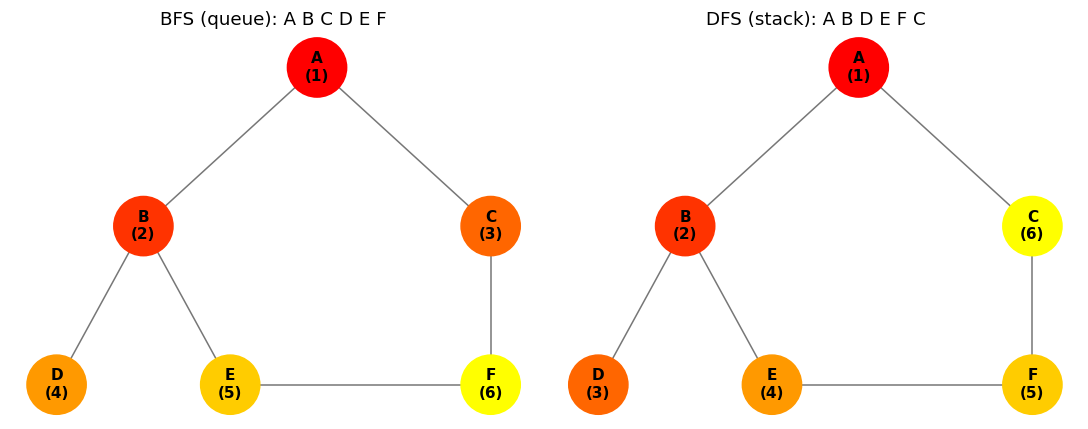

In [19]:
def draw_traversal(graph, order, title, ax):
    G = build_nx(graph)
    rank = {v: i for i, v in enumerate(order)}
    colors = [plt.cm.autumn(rank[v] / max(1, len(order) - 1)) for v in G.nodes]
    nx.draw(G, pos, ax=ax, node_color=colors, edge_color="#777",
            node_size=1500, with_labels=False)
    labels = {v: f"{v}\n({rank[v] + 1})" for v in G.nodes}
    nx.draw_networkx_labels(G, pos, labels=labels, ax=ax, font_weight="bold", font_size=10)
    ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
draw_traversal(graph, bfs_order, f"BFS (queue): {' '.join(bfs_order)}", axes[0])
draw_traversal(graph, dfs_order, f"DFS (stack): {' '.join(dfs_order)}", axes[1])
plt.tight_layout()
plt.show()

**Reading the pictures:** BFS spreads out in rings around A (A, then B and C, then D, E and F). DFS dives from A down one branch (A, B, D) until it is stuck, then backtracks to try the next unexplored path (E, F, C).

| | BFS | DFS |
|---|---|---|
| Waiting list used | **Queue** (first in, first out) | **Stack** (last in, first out) |
| Take vertices from | the **front** | the **top** |
| Add new vertices to | the **back** | the **top** |
| Exploration style | Ring by ring (wide) | One branch at a time, then backtrack (deep) |
| Shortest path (fewest edges)? | **Yes** | No |
| Typical uses | Shortest path in unweighted graphs, levels, nearest neighbour | Finding connected components, detecting cycles, maze solving, exploring all possibilities |

## 7. How Fast are BFS and DFS? (Complexity)

Let **V** be the number of vertices and **E** the number of edges.

**Time: O(V + E) for both.**
- Every vertex is added to the queue/stack and processed (essentially) once: about **V** units of work.
- When a vertex is processed we look at all its neighbours. Over the whole run, every edge is looked at twice (once from each end): about **2E** units of work.
- Total: V + 2E, which grows in proportion to V + E, written **O(V + E)**.

**Extra memory: O(V)** for both. The `visited` set and the parent/distance tables hold at most one entry per vertex, and the queue or stack never holds more than a few entries per vertex.

The cell below checks this claim by experiment. It counts the basic operations on random graphs of increasing size (with E = 3V). If the claim is right, **operations ÷ (V + E)** should stay about the same however big the graph becomes.

**Observation:** The ratio stays constant (about 1.75) as the graph grows, and the operation count forms a straight line against V + E. This confirms that both BFS and DFS run in linear time, O(V + E).

## EXERCISE
Edit the graph or the start vertex below and run the cell to watch both algorithms on your own example. Keep the dictionary format: every vertex is a key, and each edge must be listed in **both** directions.

SETUP
  Start vertex is S.
  Mark S as visited and ENQUEUE it.
  visited = ['S']
  queue   : FRONT -> [ S ] <- BACK

STEP 1
Queue before : FRONT -> [ S ] <- BACK
DEQUEUE      : S   (removed from the FRONT of the queue)
VISIT S      -> visit order so far: ['S']
Neighbours of S: ['P', 'Q']
    P: NEW -> mark visited, ENQUEUE P at the BACK (parent[P] = S, distance from S = 1)
    Q: NEW -> mark visited, ENQUEUE Q at the BACK (parent[Q] = S, distance from S = 1)
Queue after  : FRONT -> [ P ][ Q ] <- BACK
visited      : ['P', 'Q', 'S']

STEP 2
Queue before : FRONT -> [ P ][ Q ] <- BACK
DEQUEUE      : P   (removed from the FRONT of the queue)
VISIT P      -> visit order so far: ['S', 'P']
Neighbours of P: ['S', 'R']
    S: already visited -> SKIP
    R: NEW -> mark visited, ENQUEUE R at the BACK (parent[R] = P, distance from S = 2)
Queue after  : FRONT -> [ Q ][ R ] <- BACK
visited      : ['P', 'Q', 'R', 'S']

STEP 3
Queue before : FRONT -> [ Q ][ R ] <- BACK
DEQUEUE      : Q   (removed from

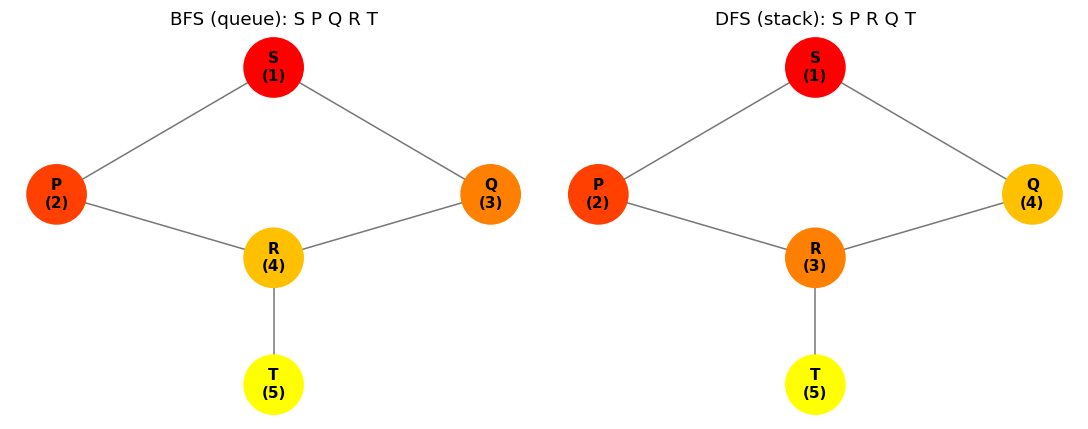

In [21]:
my_graph = {
    'S': ['P', 'Q'],
    'P': ['S', 'R'],
    'Q': ['S', 'R'],
    'R': ['P', 'Q', 'T'],
    'T': ['R'],
}
my_start = 'S'

# BFS (uses bfs_verbose from Section 4.3)
bfs_order, bfs_parent, bfs_dist = bfs_verbose(my_graph, my_start)
print("\nBFS visiting order:", bfs_order)

# DFS (uses dfs_verbose from Section 5.3)
dfs_order = dfs_verbose(my_graph, my_start)
print("\nDFS visiting order:", dfs_order)

# Check with the short versions (Sections 4.5 and 5.6)
print("\nShort BFS:", bfs(my_graph, my_start))
print("Short DFS:", dfs(my_graph, my_start))

# Side-by-side picture (draw_traversal from Section 6; it reads the global `pos`)
pos = {'S': (0, 2), 'P': (-1, 1), 'Q': (1, 1), 'R': (0, 0.5), 'T': (0, -0.5)}
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
draw_traversal(my_graph, bfs_order, f"BFS (queue): {' '.join(bfs_order)}", axes[0])
draw_traversal(my_graph, dfs_order, f"DFS (stack): {' '.join(dfs_order)}", axes[1])
plt.tight_layout()
plt.show()

## 9. Conclusion

- A **graph** is a set of vertices joined by edges, and it can be stored as an **adjacency list**.
- A **queue** is first in, first out: items join at the **back** (enqueue) and leave from the **front** (dequeue). A **stack** is last in, first out: items are pushed on, and popped from, the **top**.
- **BFS** keeps its waiting list in a **queue**. It explores the graph ring by ring and therefore finds the **shortest path** (fewest edges) from the start to every reachable vertex.
- **DFS** keeps its waiting list in a **stack** (or, in the recursive version, the call stack). It goes as deep as it can along one branch and **backtracks** at dead ends. It is useful for finding connected components and for exploring all possibilities.
- Both BFS and DFS visit each vertex and each edge a constant number of times, so both run in **O(V + E)** time and use **O(V)** extra memory. The experiment in Section 7 confirmed the linear growth.
- The two algorithms are identical except for the data structure holding the waiting list: swapping the queue for a stack turns BFS into DFS.